# Frozen Backbone – Xception và ResNet-50



## 1. Import packages và thư viện cần thiết 

Đặt kích thước ảnh, batch size, số epoch và đường dẫn lưu kết quả và random seed

`BACKBONES` gồm hai xception và resnet50 cần so sánh, mỗi backbone đi kèm hàm chuẩn hóa ảnh. Sau khi chạy lưu kết quả ở `results/frozen_<backbone>_transfer_preprocessing/` và model tại `models/frozen_<backbone>_transfer_preprocessing.keras`.

`USE_CHECKPOINTS = True`: chạy xong sẽ tạo checkpoint trong `models/`, có thể nạp lại và bỏ qua bước train; đặt `False` để train lại từ đầu.


In [ ]:
from pathlib import Path
import json
import tensorflow as tf
from tensorflow.keras import layers, callbacks
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

ROOT = Path.cwd() if (Path.cwd() / 'notebooks').exists() else Path.cwd().parent
CLASS_NAMES = ['fire', 'nofire', 'smoke', 'smokefire']
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 30
SEED = 42
USE_CHECKPOINTS = True  
BACKBONES = {
    'xception': (tf.keras.applications.Xception, tf.keras.applications.xception.preprocess_input),
    'resnet50': (tf.keras.applications.ResNet50, tf.keras.applications.resnet50.preprocess_input),
}
RUNS = [(f'frozen_{name}', name) for name in BACKBONES]

def result_dir(run):
    path = ROOT / 'results' / f'{run}_transfer_preprocessing'
    path.mkdir(parents=True, exist_ok=True)
    return path

def model_path(run):
    (ROOT / 'models').mkdir(exist_ok=True)
    return ROOT / 'models' / f'{run}_transfer_preprocessing.keras'

tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0 | GPU: []


## 2. Xử lý ảnh
- Ảnh processed là RGB 224×224, không cần resize.
- Backbone chuẩn hóa ảnh theo weight ImageNet của nó đã được huấn luyện, bằng hàm `preprocess_input` của Keras: Xception đưa pixel về [-1, 1]; ResNet-50 đổi RGB → BGR rồi trừ mean ImageNet.
- Train được shuffle; validation và test giữ nguyên để đối chiếu preds với true label. 

In [2]:
df = pd.read_csv(ROOT / 'data/split.csv')
df = df[df['status'] == 'ok'].copy()
assert (df['label'].map({name: i for i, name in enumerate(CLASS_NAMES)}) == df['class_index']).all()
assert set(df['split']) == {'train', 'val', 'test'}
display(pd.crosstab(df['split'], df['label'])[CLASS_NAMES])

label,fire,nofire,smoke,smokefire
split,,,,
test,200,200,200,200
train,800,800,800,800
val,200,200,200,200


In [3]:
def load_image(filepath, label):
    image = tf.io.decode_jpeg(tf.io.read_file(filepath), channels=3)
    image = tf.ensure_shape(image, [224, 224, 3])
    return tf.cast(image, tf.float32), label


def make_dataset(split, preprocess, shuffle=False):
    part = df[df['split'] == split].reset_index(drop=True)
    paths = [str(ROOT / p) for p in part['processed_filepath']]
    assert paths and all(Path(p).is_file() for p in paths), 'Thiếu ảnh processed.'
    ds = tf.data.Dataset.from_tensor_slices((paths, part['class_index'].astype('int32')))
    if shuffle:
        ds = ds.shuffle(len(part), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda image, label: (preprocess(image), label), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


test_df = df[df['split'] == 'test'].reset_index(drop=True)
y_true = test_df['class_index'].to_numpy()

## 3. Build mô hình

- Lật ngang ảnh khi train → backbone ImageNet → Dropout(0,45) → Dense(512, ReLU) → BatchNormalization → Dropout(0,2) → Dense(4, Softmax).

- Backbone bỏ lớp phân loại gốc của ImageNet (`include_top=False`) và lấy trung bình toàn cục (`pooling='avg'`), nên mỗi ảnh thành một vector 2048 đặc trưng. Backbone được frozen (`trainable = False`): trọng số không đổi và các lớp BatchNormalization bên trong giữ thống kê ImageNet. Chỉ head prediction được thay đổi trọng số trong quá trình train.

- Dùng AdamW với lr 0,0005 và weight decay 0,0001. Loss dùng `sparse_categorical_crossentropy`. 

In [4]:
def build_model(name):
    backbone = BACKBONES[name][0](include_top=False, weights='imagenet',
                                  input_shape=(*IMAGE_SIZE, 3), pooling='avg')
    backbone.trainable = False
    model = tf.keras.Sequential([
        layers.Input(shape=(*IMAGE_SIZE, 3)),
        layers.RandomFlip('horizontal', seed=SEED),
        backbone,
        layers.Dropout(0.45),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(len(CLASS_NAMES), activation='softmax'),
    ], name=f'frozen_{name}')
    model.compile(optimizer=tf.keras.optimizers.AdamW(5e-4, weight_decay=1e-4),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model


for name in BACKBONES:
    build_model(name).summary()

Model: "frozen_xception"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 2048)           │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,914,668 (83.60 MB)

 Trainable params: 1,052,164 (4.01 MB)

 Non-trainable params: 20,862,504 (79.58 MB)

Model: "frozen_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 2048)           │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,640,900 (94.00 MB)

 Trainable params: 1,052,164 (4.01 MB)

 Non-trainable params: 23,588,736 (89.98 MB)

## 4. Train mô hình

Mỗi backbone train tối đa 30 epoch, theo dõi validation loss:

- Lưu model có validation loss thấp nhất.
- Giảm lr một nửa sau 2 epoch không cải thiện.
- Early stopping sau 6 epoch không cải thiện.

- Với `USE_CHECKPOINTS = True`, đã có checkpoint trong `models/` thì bỏ qua bước train; biểu đồ và metrics đọc kết quả train tử file `results/frozen_<backbone>_transfer_preprocessing/metrics.json`.

In [ ]:
for run, name in RUNS:
    if USE_CHECKPOINTS and model_path(run).exists():
        print('Dùng checkpoint có sẵn, bỏ qua training:', model_path(run).name)
        continue
    print('Train model:', run)
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    preprocess = BACKBONES[name][1]
    model = build_model(name)
    training_callbacks = [
        callbacks.ModelCheckpoint(model_path(run), monitor='val_loss', save_best_only=True),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2),
        callbacks.EarlyStopping(monitor='val_loss', patience=6),
        callbacks.CSVLogger(result_dir(run) / 'training_history.csv'),
    ]
    model.fit(make_dataset('train', preprocess, shuffle=True), validation_data=make_dataset('val', preprocess),
              epochs=EPOCHS, callbacks=training_callbacks, verbose=2)

===== frozen_xception

Epoch 1/30


c:\Users\DELL\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


100/100 - 1174s - 12s/step - accuracy: 0.7484 - loss: 0.7103 - val_accuracy: 0.7900 - val_loss: 0.4777 - learning_rate: 5.0000e-04
Epoch 2/30
100/100 - 1565s - 16s/step - accuracy: 0.8203 - loss: 0.4799 - val_accuracy: 0.8625 - val_loss: 0.3458 - learning_rate: 5.0000e-04
Epoch 3/30


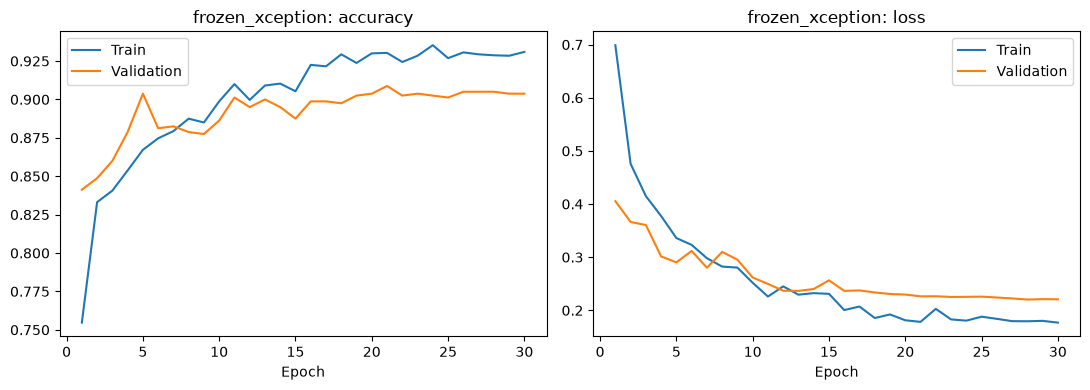

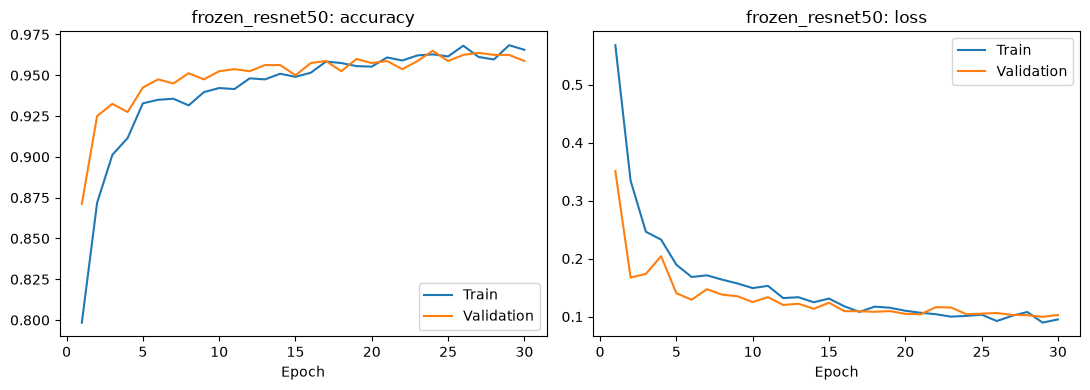

In [ ]:
for run, name in RUNS:
    history = pd.read_csv(result_dir(run) / 'training_history.csv')
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric in zip(axes, ['accuracy', 'loss']):
        ax.plot(history['epoch'] + 1, history[metric], label='Train')
        ax.plot(history['epoch'] + 1, history['val_' + metric], label='Validation')
        ax.set(xlabel='Epoch', title=f'{run}: {metric}')
        ax.legend()
    plt.tight_layout()
    plt.savefig(result_dir(run) / 'accuracy_loss_curves.png', dpi=150)
    plt.show()

## 5. Test Eval

- Lấy model tốt nhất của từng lần chạy, đánh giá trên test. Accuracy là tỷ lệ dự đoán đúng; macro F1 là trung bình F1 của 4 lớp.

Confusion matrix có hàng là true label, cột là pred label. Xem thêm hai chiều negative preds smoke ↔ smokefire. 

===== frozen_xception


,precision,recall,f1-score,support
fire,0.9416,0.645,0.7656,200.00
nofire,0.9698,0.965,0.9674,200.00
smoke,0.6754,0.905,0.7735,200.00
smokefire,0.5765,0.565,0.5707,200.00
accuracy,0.7700,0.770,0.7700,0.77
macro avg,0.7908,0.770,0.7693,800.00
weighted avg,0.7908,0.770,0.7693,800.00


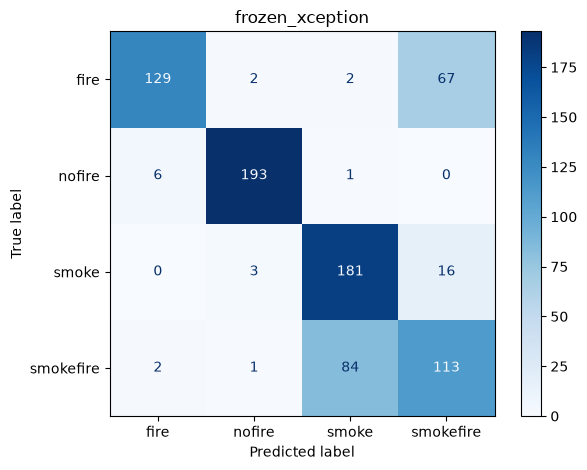

Accuracy: 77.00% | Macro F1: 0.7693
smokefire → smoke: 84 | smoke → smokefire: 16


===== frozen_resnet50


,precision,recall,f1-score,support
fire,0.9926,0.675,0.8036,200.000
nofire,0.9851,0.990,0.9875,200.000
smoke,0.7864,0.810,0.7980,200.000
smokefire,0.6109,0.785,0.6871,200.000
accuracy,0.8150,0.815,0.8150,0.815
macro avg,0.8438,0.815,0.8191,800.000
weighted avg,0.8438,0.815,0.8191,800.000


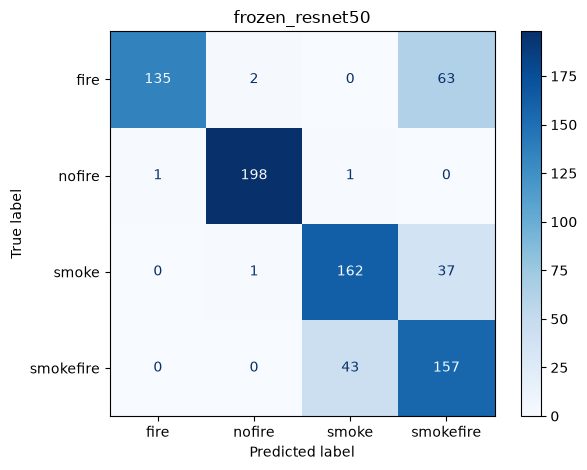

Accuracy: 81.50% | Macro F1: 0.8191
smokefire → smoke: 43 | smoke → smokefire: 37


In [ ]:
results = {}
for run, name in RUNS:
    tf.keras.backend.clear_session()
    test_ds = make_dataset('test', BACKBONES[name][1])
    best_model = tf.keras.models.load_model(model_path(run))
    loss, accuracy = best_model.evaluate(test_ds, verbose=0)
    probabilities = best_model.predict(test_ds, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    assert np.isclose(accuracy, (y_true == y_pred).mean())
    report = classification_report(y_true, y_pred, labels=range(len(CLASS_NAMES)),
        target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    matrix = confusion_matrix(y_true, y_pred, labels=range(len(CLASS_NAMES)))
    results[run] = {'loss': loss, 'accuracy': accuracy, 'probabilities': probabilities,
                    'report': report, 'matrix': matrix, 'parameter_count': best_model.count_params(),
                    'trainable_parameter_count': int(sum(np.prod(w.shape) for w in best_model.trainable_weights))}

    print('', run)
    display(pd.DataFrame(report).T.round(4))
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(cmap='Blues')
    plt.title(run)
    plt.tight_layout()
    plt.savefig(result_dir(run) / 'confusion_matrix.png', dpi=150)
    plt.show()
    print(f'Accuracy: {accuracy:.2%} | Macro F1: {report["macro avg"]["f1-score"]:.4f}')
    print('smokefire → smoke:', matrix[3, 2], '| smoke → smokefire:', matrix[2, 3])

## 6. Lưu kết quả

Với mỗi backbone, lưu metrics, preds results, danh sách false negative labels và confusion matrix tại `results/frozen_<backbone>_transfer_preprocessing/`. Bảng cuối so sánh hai backbone trên test set.

In [ ]:
for run, name in RUNS:
    r = results[run]
    out = result_dir(run)
    history = pd.read_csv(out / 'training_history.csv')
    y_pred = r['probabilities'].argmax(axis=1)
    predictions = test_df[['filepath', 'processed_filepath', 'label', 'class_index']].copy()
    predictions['predicted_label'] = np.array(CLASS_NAMES)[y_pred]
    predictions['confidence'] = r['probabilities'].max(axis=1)
    predictions.to_csv(out / 'predictions.csv', index=False)
    predictions[y_true != y_pred].to_csv(out / 'misclassified.csv', index=False)
    pd.DataFrame(r['report']).T.to_csv(out / 'classification_report.csv', index_label='class')
    pd.DataFrame(r['matrix'], index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        out / 'confusion_matrix.csv', index_label='true_label')

    metrics = {
        'test_accuracy': float(r['accuracy']), 'test_loss': float(r['loss']),
        'macro_f1': r['report']['macro avg']['f1-score'],
        'misclassified_count': int((y_true != y_pred).sum()),
        'parameter_count': r['parameter_count'],
        'trainable_parameter_count': r['trainable_parameter_count'],
        'best_epoch': int(history['val_loss'].argmin()) + 1,
        'best_val_loss': float(history['val_loss'].min()),
        'class_names': CLASS_NAMES, 'image_size': list(IMAGE_SIZE), 'seed': SEED,
        'preprocessing': {'source': 'processed_filepath', 'manifest': 'data/split.csv',
            'normalization': f'keras.applications.{name}.preprocess_input', 'augmentation': 'horizontal_flip'},
        'training_config': {'backbone': name, 'backbone_frozen': True,
            'head': 'Dropout 0.45 - Dense 512 ReLU - BatchNorm - Dropout 0.2 - Dense 4',
            'optimizer': 'AdamW', 'learning_rate': 5e-4, 'weight_decay': 1e-4,
            'batch_size': BATCH_SIZE, 'epochs': EPOCHS, 'early_stopping_patience': 6},
        'tensorflow_version': tf.__version__,
    }
    (out / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
    model_path(run).with_suffix('.labels.json').write_text(json.dumps(CLASS_NAMES), encoding='utf-8')

pd.DataFrame({run: {'test_accuracy': r['accuracy'], 'macro_f1': r['report']['macro avg']['f1-score'],
                    'trainable_params': r['trainable_parameter_count']}
              for run, r in results.items()}).T.round(4)

,test_accuracy,macro_f1,trainable_params
frozen_xception,0.770,0.7693,1052164.0
frozen_resnet50,0.815,0.8191,1052164.0
